# Step 1a — Otsu binarization (visual check)

Calls the functions in `src/thresholding.py`. This notebook only plots; all thresholding logic lives in `src/`.

For each image: **grayscale** | **histogram with Otsu threshold t\*** | **between-class variance σ_B²(t)** | **binary result (ink = white)**.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.thresholding import load_gray, preprocess, otsu_threshold, otsu_binarize

BLUR = 5  # Gaussian kernel used before Otsu (0 = no blur)

In [3]:
def show_otsu(gray, title, blur_ksize=BLUR):
    """4-panel view of Otsu on one grayscale image."""
    smoothed = preprocess(gray, blur_ksize)
    t, sigma_b2 = otsu_threshold(smoothed)
    binary, _ = otsu_binarize(gray, blur_ksize)

    fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
    ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0].set_title(f"{title}: grayscale")
    ax[1].hist(smoothed.ravel(), bins=256, range=(0, 256), color="0.4")
    ax[1].axvline(t, color="r", label=f"t* = {t}"); ax[1].set_yscale("log")
    ax[1].set_title("histogram (log count)"); ax[1].legend()
    ax[2].plot(sigma_b2); ax[2].axvline(t, color="r")
    ax[2].set_title("between-class variance σ_B²(t)"); ax[2].set_xlabel("t")
    ax[3].imshow(binary, cmap="gray"); ax[3].set_title(f"Otsu binary (ink = 255), t* = {t}")
    for a in (ax[0], ax[3]):
        a.axis("off")
    plt.tight_layout(); plt.show()
    return binary, t

## 1. Synthetic check (no photos needed)

Dark handwriting-like strokes on light paper with mild noise. Otsu should separate them cleanly: the histogram is bimodal (a small ink peak and a large paper peak).

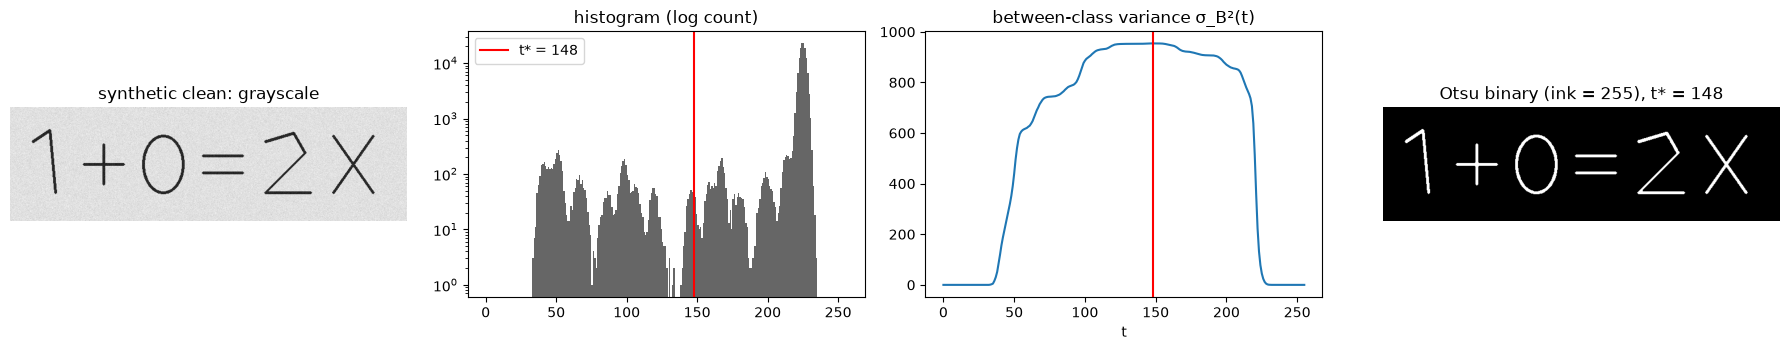

In [4]:
rng = np.random.default_rng(0)

def synthetic_expression(h=200, w=700):
    img = np.full((h, w), 225, np.uint8)
    pts = lambda *xy: np.array(xy, np.int32).reshape(-1, 1, 2)
    ink, th = 40, 4
    cv2.polylines(img, [pts(40,60, 70,40, 80,150)], False, ink, th)                                    # "1"
    cv2.line(img, (130,100), (200,100), ink, th); cv2.line(img, (165,65), (165,135), ink, th)          # "+"
    cv2.ellipse(img, (270,100), (35,50), 0, 0, 360, ink, th)                                           # "0"
    cv2.line(img, (340,85), (410,85), ink, th); cv2.line(img, (340,115), (410,115), ink, th)           # "="
    cv2.polylines(img, [pts(450,60, 500,45, 520,80, 450,150, 530,150)], False, ink, th)                # "2"
    cv2.line(img, (570,50), (640,150), ink, th); cv2.line(img, (640,50), (570,150), ink, th)           # "x"
    noise = rng.normal(0, 8, img.shape)
    return np.clip(img + noise, 0, 255).astype(np.uint8)

clean = synthetic_expression()
_ = show_otsu(clean, "synthetic clean")

### Same image under uneven lighting

Multiply by a left→right illumination gradient (bright on the left, dark on the right). The paper on the right becomes as dark as the ink on the left, so no single global threshold can separate them. Otsu should fail visibly (the right side turns to ink). This is the motivation for adaptive thresholding next.

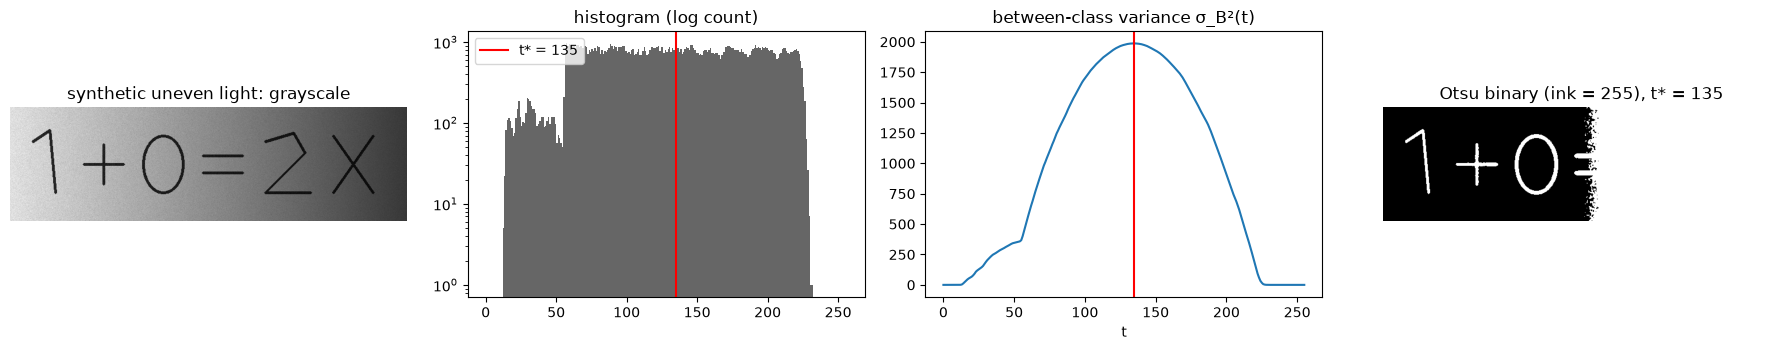

In [5]:
h, w = clean.shape
gradient = np.linspace(1.0, 0.25, w)[None, :]
uneven = np.clip(clean.astype(np.float64) * gradient, 0, 255).astype(np.uint8)
_ = show_otsu(uneven, "synthetic uneven light")

## 2. Own photos

Put photos in `data/raw/photos/` (naming suggestion: `<id>_<condition>.jpg`, condition ∈ clean / uneven / texture / faint).

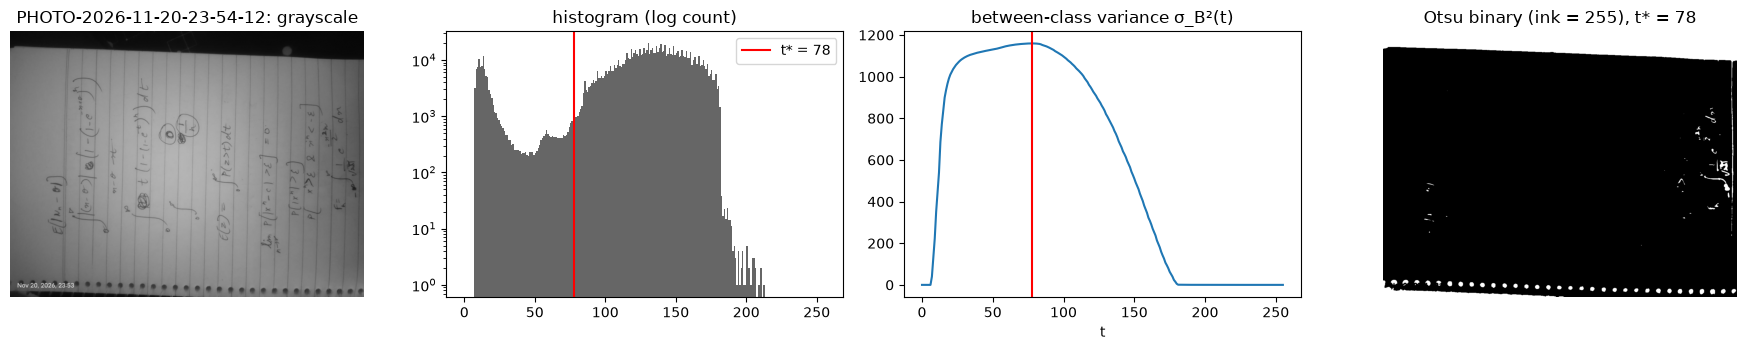

In [6]:
photo_dir = ROOT / "data" / "raw" / "photos"
exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
photos = sorted(p for p in photo_dir.glob("*") if p.suffix.lower() in exts) if photo_dir.exists() else []

if not photos:
    print(f"No photos found in {photo_dir} — add some and re-run this cell.")
for p in photos:
    show_otsu(load_gray(p), p.stem)